In [1]:
from run_dom_color import *
from album_store import *
from optimize import *
import matplotlib.pyplot as plt

/home/wkuki/spotiled/optimization/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
store = AlbumStore()
albums = load_albums(store)

In [37]:
print(albums[0])
saved_gray = dom_color_gray

LoadedAlbum(album=Album(id='3dck2tBxGfxj9m3CguDgjb', image_filename='Metallica-Metallica (Remastered 2021).jpg', color='#383838FF'), spotify_color=RGB(r=56, g=56, b=56), pixels=array([65, 65, 65, ..., 65, 65, 65], shape=(4096,), dtype=uint16))


In [38]:
PARAMS = {'alpha': 1, 'beta': 66, 'gamma': 24}
PARAMS = {'alpha': 1, 'beta': 0, 'gamma': 24}

In [39]:
histograms = make_histograms(PARAMS)
evaluated = evaluate(albums, *histograms)
Y = errors_of(evaluated)

In [40]:
H, X = np.histogram(Y, bins=20)

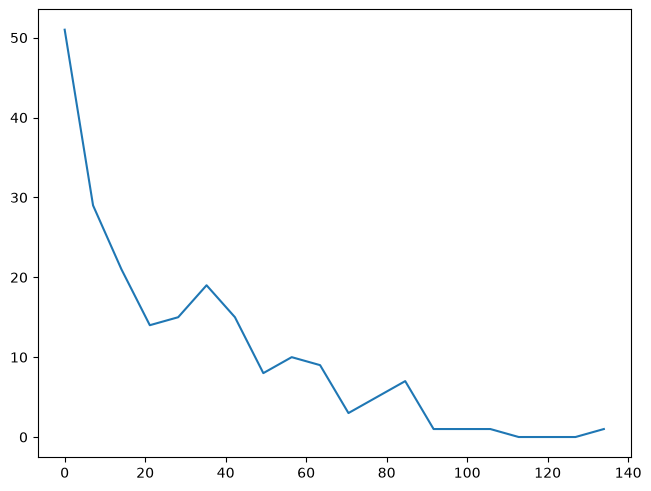

In [41]:
fig, ax = plt.subplots(1, layout='constrained')
ax.plot(X[:-1], H)

In [42]:
sorted_ix = np.argsort(Y)

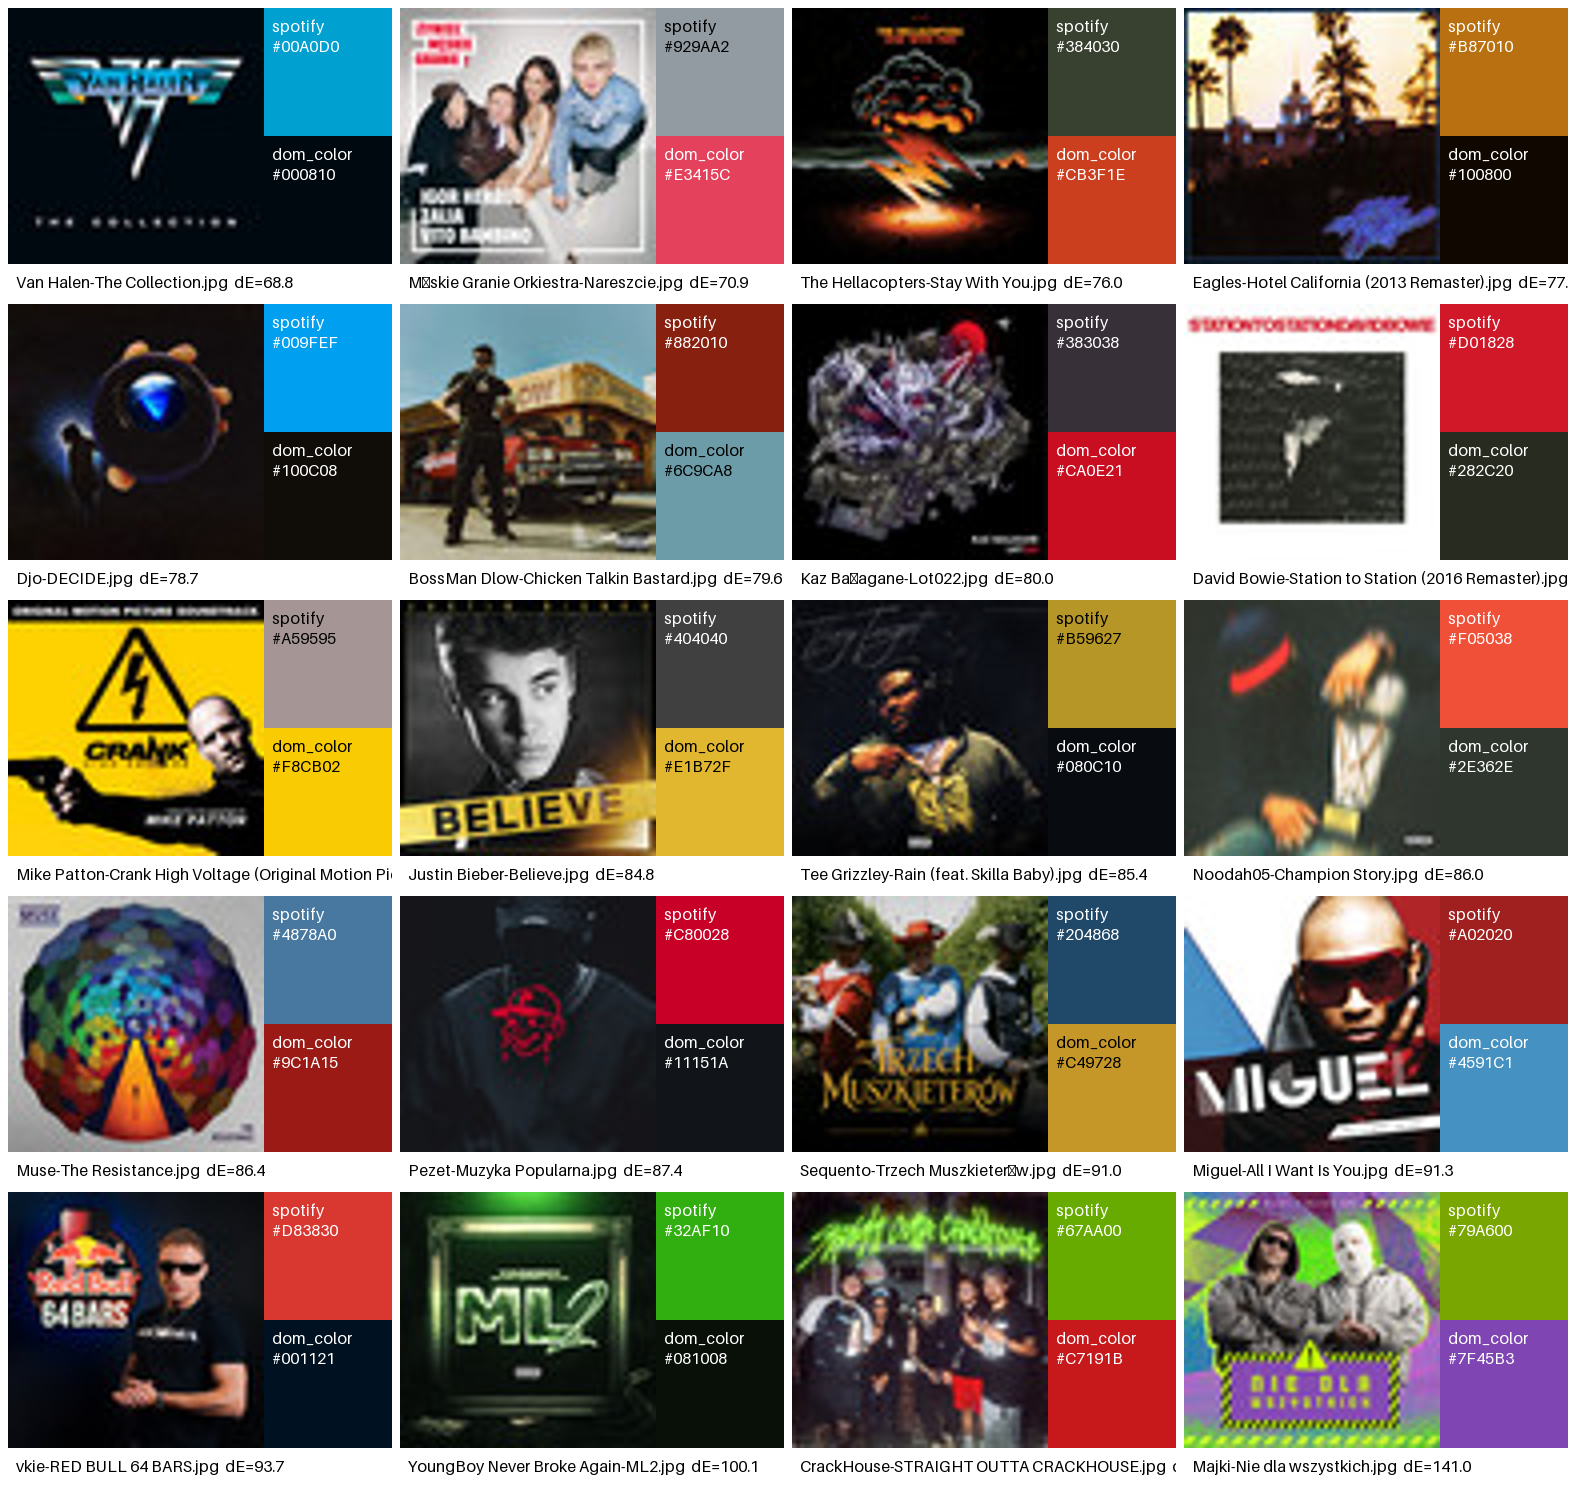

In [53]:
chosen_albums = [evaluated[ix] for ix in sorted_ix[-20:]]
make_collage(store, chosen_albums)

In [44]:
GRAY_SATURATION = 0.1  # HSV saturation below this counts as gray

def saturation(colors: list[RGB]) -> np.ndarray:
    rgb = metrics.rgb_to_array(colors)
    hi, lo = rgb.max(axis=1), rgb.min(axis=1)
    return np.divide(hi - lo, hi, out=np.zeros_like(hi), where=hi > 0)

spotify_gray = np.flatnonzero(saturation([e.loaded.spotify_color for e in evaluated]) < GRAY_SATURATION)
dom_color_gray = np.flatnonzero(saturation([e.predicted for e in evaluated]) < GRAY_SATURATION)
print(f"spotify gray: {len(spotify_gray)}, dom_color gray: {len(dom_color_gray)}")

spotify gray: 35, dom_color gray: 23


In [50]:
spotify_gray_albums = [evaluated[ix] for ix in spotify_gray]
dom_color_gray_albums = [evaluated[ix] for ix in saved_gray]

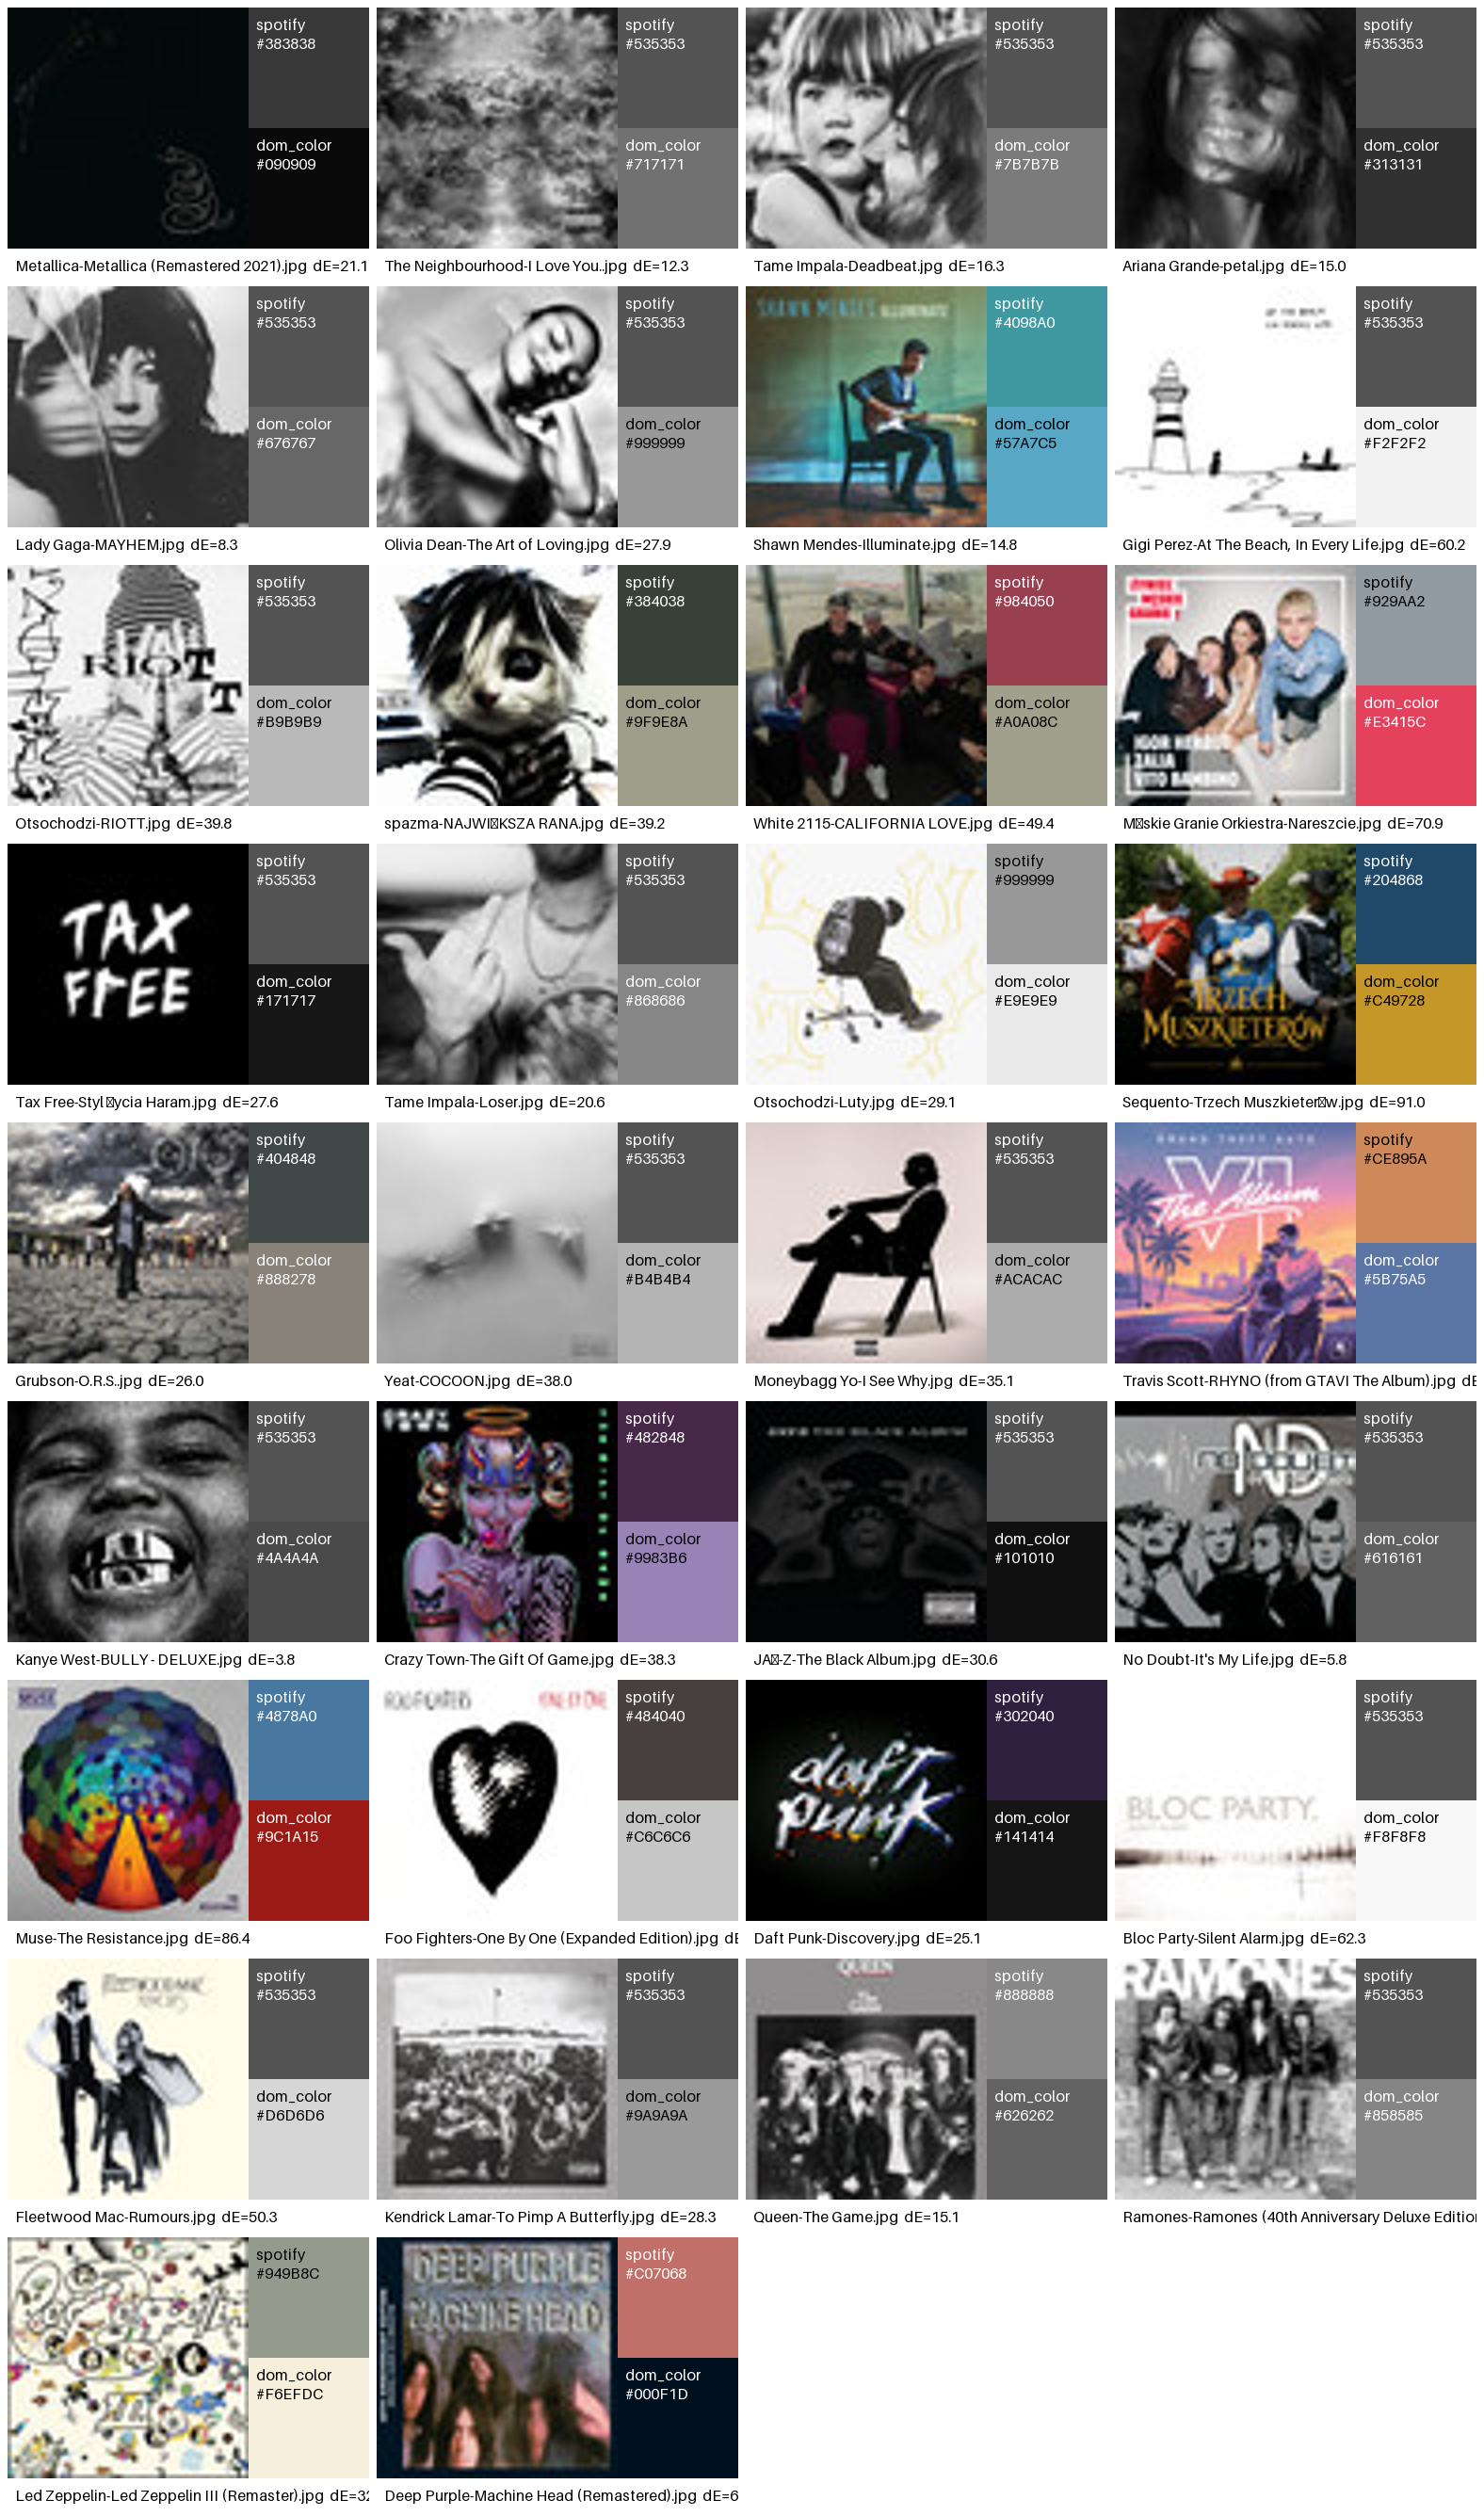

In [51]:
make_collage(store, dom_color_gray_albums)

In [47]:
dom_color_gray

array([  0,  21,  22,  25,  29,  34,  40,  50,  67,  69,  75,  89,  95,
       107, 141, 145, 149, 152, 160, 164, 165, 168, 169])